# Домашнее задание 5: Классификация MNIST



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_style('whitegrid')
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

## 1. Загрузка MNIST


In [ ]:
mnist = fetch_openml('mnist_784', version=1, as_frame=False)
X = mnist.data.astype(np.float32) / 255.0
y = mnist.target.astype(int)

print('Размер X:', X.shape)
print('Размер y:', y.shape)
print('Уникальные классы:', np.unique(y))

Размер X: (70000, 784)
Размер y: (70000,)
Уникальные классы: [0 1 2 3 4 5 6 7 8 9]


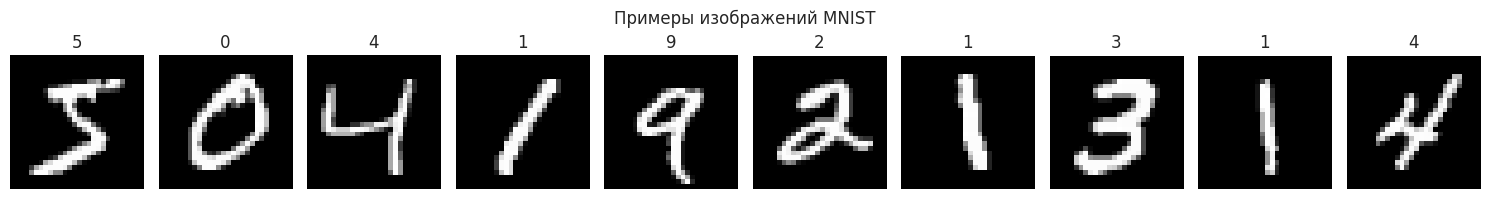

In [ ]:
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for i, ax in enumerate(axes):
    ax.imshow(X[i].reshape(28, 28), cmap='gray')
    ax.set_title(str(y[i]))
    ax.axis('off')
plt.suptitle('Примеры изображений MNIST')
plt.tight_layout()
plt.show()

Задание 2

In [5]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42, stratify=y_train_val
)

print('Train:', X_train.shape, y_train.shape)
print('Validation:', X_val.shape, y_val.shape)
print('Test:', X_test.shape, y_test.shape)

Train: (42000, 784) (42000,)
Validation: (14000, 784) (14000,)
Test: (14000, 784) (14000,)


## 3. Масштабирование


In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

## 4. Обучение и сравнение моделей

In [7]:
models = {
    'LogisticRegression': LogisticRegression(max_iter=1000, n_jobs=-1, solver='lbfgs', multi_class='multinomial'),
    'RandomForest': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    'MLPClassifier': MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=30, random_state=42, early_stopping=True),
}

results = []

for name, model in models.items():
    print(f'\n=== Обучение {name} ===')
    model.fit(X_train_scaled, y_train)
    y_val_pred = model.predict(X_val_scaled)
    val_acc = accuracy_score(y_val, y_val_pred)
    print(f'Validation accuracy: {val_acc:.4f}')
    results.append({'model': name, 'val_accuracy': val_acc, 'model_obj': model})

results_df = pd.DataFrame([{k: v for k, v in r.items() if k != 'model_obj'} for r in results])
display(results_df.sort_values('val_accuracy', ascending=False))


=== Обучение LogisticRegression ===


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Validation accuracy: 0.9124

=== Обучение RandomForest ===
Validation accuracy: 0.9671

=== Обучение MLPClassifier ===
Validation accuracy: 0.9717


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


,model,val_accuracy
2,MLPClassifier,0.9717
1,RandomForest,0.9671
0,LogisticRegression,0.9124


## 5. Оценка лучшей модели на тесте



In [8]:
best_result = max(results, key=lambda r: r['val_accuracy'])
best_model = best_result['model_obj']
best_name = best_result['model']

y_test_pred = best_model.predict(X_test_scaled)
test_acc = accuracy_score(y_test, y_test_pred)
print(f'Лучшая модель: {best_name}')
print(f'Test accuracy: {test_acc:.4f}')
print('\nClassification report:')
print(classification_report(y_test, y_test_pred))

Лучшая модель: MLPClassifier
Test accuracy: 0.9716

Classification report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      1381
           1       0.98      0.98      0.98      1575
           2       0.97      0.97      0.97      1398
           3       0.97      0.96      0.97      1428
           4       0.97      0.97      0.97      1365
           5       0.97      0.96      0.97      1263
           6       0.98      0.98      0.98      1375
           7       0.97      0.97      0.97      1459
           8       0.97      0.96      0.96      1365
           9       0.96      0.96      0.96      1391

    accuracy                           0.97     14000
   macro avg       0.97      0.97      0.97     14000
weighted avg       0.97      0.97      0.97     14000



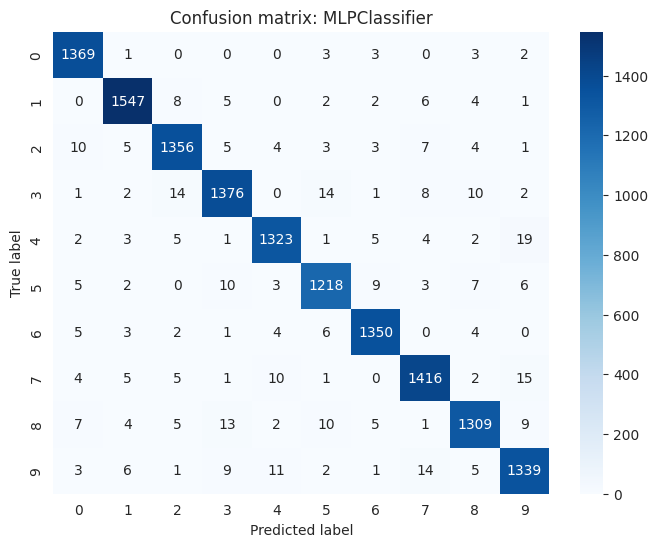

In [9]:
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f'Confusion matrix: {best_name}')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.show()

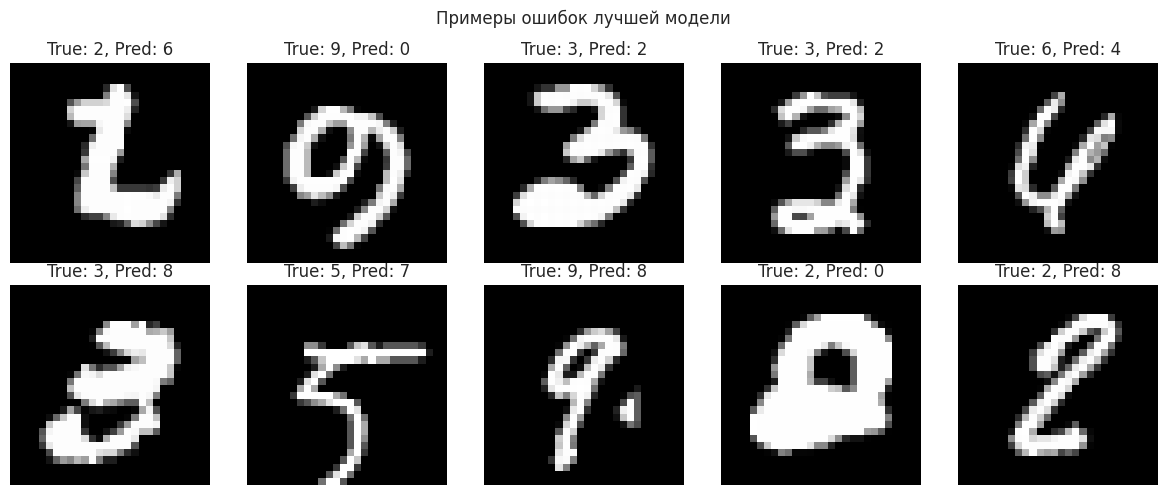

In [10]:
misclassified_idx = np.where(y_test_pred != y_test)[0][:10]
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, idx in zip(axes.ravel(), misclassified_idx):
    ax.imshow(X_test[idx].reshape(28, 28), cmap='gray')
    ax.set_title(f'True: {y_test[idx]}, Pred: {y_test_pred[idx]}')
    ax.axis('off')
plt.suptitle('Примеры ошибок лучшей модели')
plt.tight_layout()
plt.show()

## 6. Выводы

- **LogisticRegression** даёт хорошую базовую точность и быстро обучается.
- **RandomForest** обычно точнее, но требует больше памяти и времени.
- **MLPClassifier** может показать лучшую точность среди перечисленных, но чувствителен к гиперпараметрам.
- Лучшая модель выбирается по validation accuracy, а финальное качество подтверждается на отложенном test.
- Основные ошибки — неоднозначные написания цифр (например, 4/9, 3/5, 7/1), что видно по confusion matrix.